# ✅ Missing Data Handling: Complete Case Analysis (CCA)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 1) Load Dataset
# ==========================================================

df = pd.read_csv('data_science_job.csv')

print("✅ Dataset Shape:", df.shape)
print(df.head(), "\n")

✅ Dataset Shape: (19158, 13)
   enrollee_id      city  city_development_index gender  \
0         8949  city_103                   0.920   Male   
1        29725   city_40                   0.776   Male   
2        11561   city_21                   0.624    NaN   
3        33241  city_115                   0.789    NaN   
4          666  city_162                   0.767   Male   

       relevent_experience enrolled_university education_level  \
0  Has relevent experience       no_enrollment        Graduate   
1   No relevent experience       no_enrollment        Graduate   
2   No relevent experience    Full time course        Graduate   
3   No relevent experience                 NaN        Graduate   
4  Has relevent experience       no_enrollment         Masters   

  major_discipline  experience company_size    company_type  training_hours  \
0             STEM        20.0          NaN             NaN            36.0   
1             STEM        15.0        50-99         Pvt Ltd  

In [3]:
# 2) Missing Value Percentage (Overall)
# ==========================================================

missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)

print("✅ Missing % in each column:")
print(missing_percent, "\n")

✅ Missing % in each column:
company_type              32.049274
company_size              30.994885
gender                    23.530640
major_discipline          14.683161
training_hours             3.998330
city_development_index     2.500261
education_level            2.401086
enrolled_university        2.014824
experience                 0.339284
relevent_experience        0.000000
city                       0.000000
enrollee_id                0.000000
target                     0.000000
dtype: float64 



In [4]:
# 3) Select Columns with Missing Between (0% and 5%)
# ==========================================================
# Reason: CCA is safer when missing is LOW (small %),
# otherwise rows drop too much and bias increases.

cols = [col for col in df.columns if 0 < df[col].isnull().mean() < 0.05]

print("✅ Columns selected for CCA (0% < missing < 5%):")
print(cols, "\n")

print("✅ Sample of selected columns:")
print(df[cols].sample(5), "\n")

✅ Columns selected for CCA (0% < missing < 5%):
['city_development_index', 'enrolled_university', 'education_level', 'experience', 'training_hours'] 

✅ Sample of selected columns:
       city_development_index enrolled_university education_level  experience  \
9463                    0.920       no_enrollment     High School        20.0   
5596                    0.769       no_enrollment         Masters         9.0   
6006                    0.920       no_enrollment        Graduate         9.0   
15416                   0.920       no_enrollment        Graduate         9.0   
10442                   0.640       no_enrollment        Graduate        11.0   

       training_hours  
9463              NaN  
5596             50.0  
6006            112.0  
15416            27.0  
10442           176.0   



In [5]:
# ==========================================================
# 4) Apply CCA (drop rows where any selected col is missing)
# ==========================================================

new_df = df[cols].dropna()

print("✅ Original Shape:", df.shape)
print("✅ New CCA Shape:", new_df.shape)

retained_ratio = len(new_df) / len(df)
print(f"✅ Data retained after CCA: {retained_ratio:.4f} ({retained_ratio*100:.2f}%)\n")


✅ Original Shape: (19158, 13)
✅ New CCA Shape: (17182, 5)
✅ Data retained after CCA: 0.8969 (89.69%)



✅ Numerical columns in selected set: ['city_development_index', 'experience', 'training_hours'] 



C:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128204 (\N{PUSHPIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


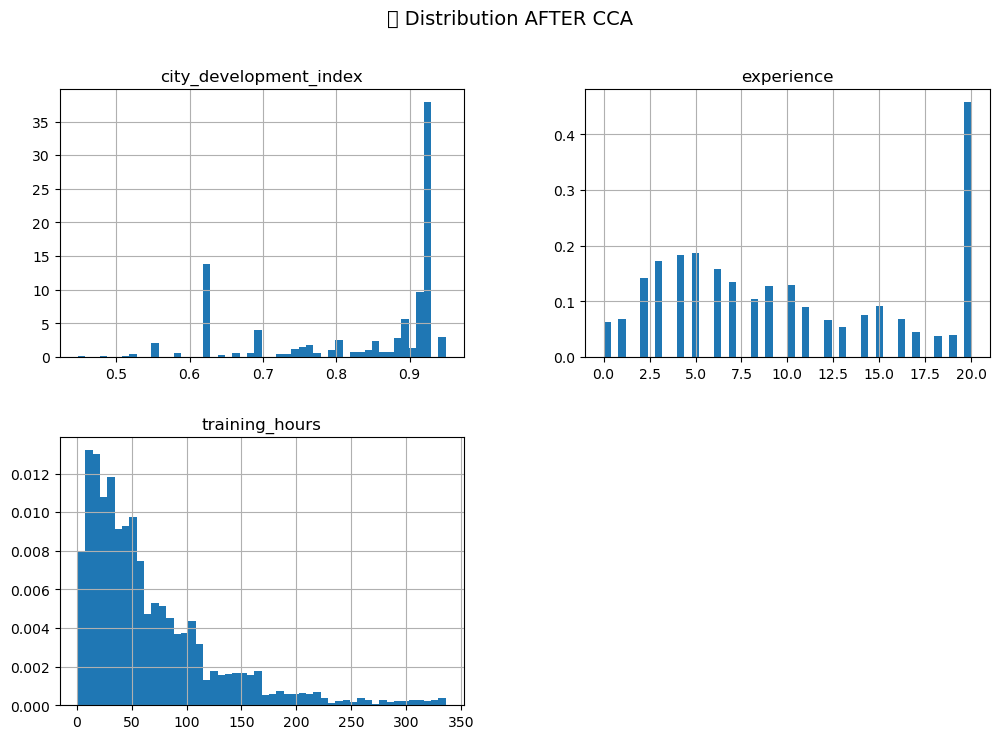

In [6]:
# ==========================================================
# 5) Distribution Check for Numerical Columns
# ==========================================================
# Idea: after dropping rows, distribution should remain similar.
# If it changes a lot => CCA is introducing bias.

num_cols = new_df.select_dtypes(include=['int64','float64']).columns.tolist()

print("✅ Numerical columns in selected set:", num_cols, "\n")

# Histograms (after CCA)
new_df[num_cols].hist(bins=50, figsize=(12, 8), density=True)
plt.suptitle("📌 Distribution AFTER CCA", fontsize=14)
plt.show()


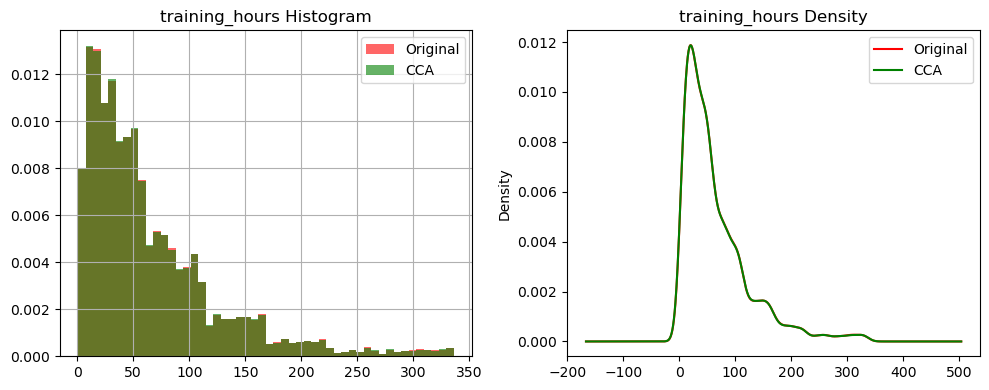

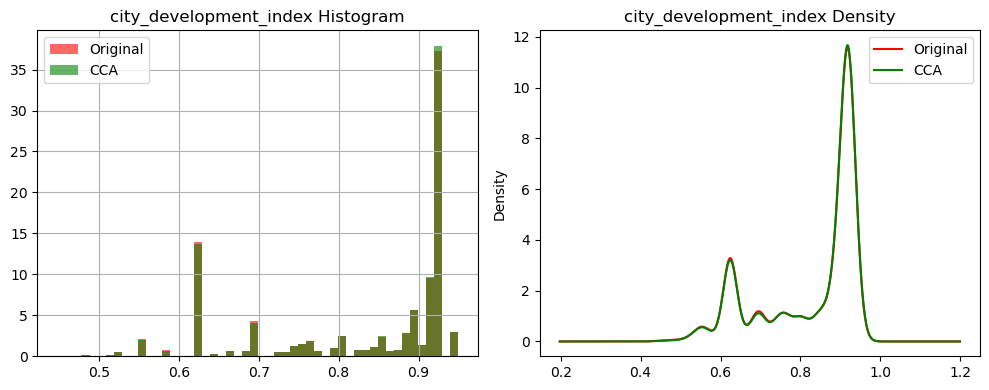

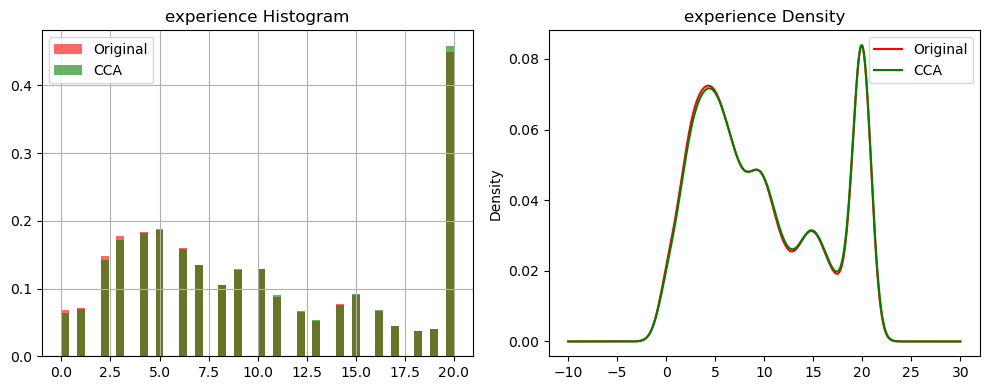

In [7]:
# ==========================================================
# 6) Compare Original vs CCA distributions (Numerical)
# ==========================================================
def compare_hist_and_density(col):
    fig = plt.figure(figsize=(10, 4))
    ax = fig.add_subplot(121)

    # Histogram overlay
    df[col].dropna().hist(bins=50, ax=ax, density=True, color='red', alpha=0.6, label='Original')
    new_df[col].hist(bins=50, ax=ax, density=True, color='green', alpha=0.6, label='CCA')
    ax.set_title(f"{col} Histogram")
    ax.legend()

    ax2 = fig.add_subplot(122)

    # Density plot overlay
    df[col].dropna().plot.density(ax=ax2, color='red', label='Original')
    new_df[col].plot.density(ax=ax2, color='green', label='CCA')
    ax2.set_title(f"{col} Density")
    ax2.legend()

    plt.tight_layout()
    plt.show()


# Compare main numerical columns
for col in ['training_hours', 'city_development_index', 'experience']:
    if col in cols:
        compare_hist_and_density(col)


✅ Category Distribution Comparison for: enrolled_university
                     original       cca
enrolled_university                    
no_enrollment        0.721213  0.735188
Full time course     0.196106  0.200733
Part time course     0.062533  0.064079
NaN                  0.020148  0.000000


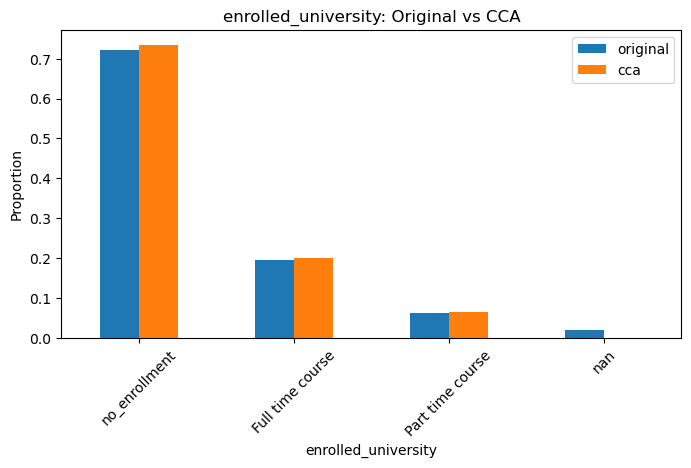


✅ Category Distribution Comparison for: education_level
                 original       cca
education_level                    
Graduate         0.605387  0.619835
Masters          0.227633  0.234082
High School      0.105282  0.107380
NaN              0.024011  0.000000
Phd              0.021610  0.022116
Primary School   0.016077  0.016587


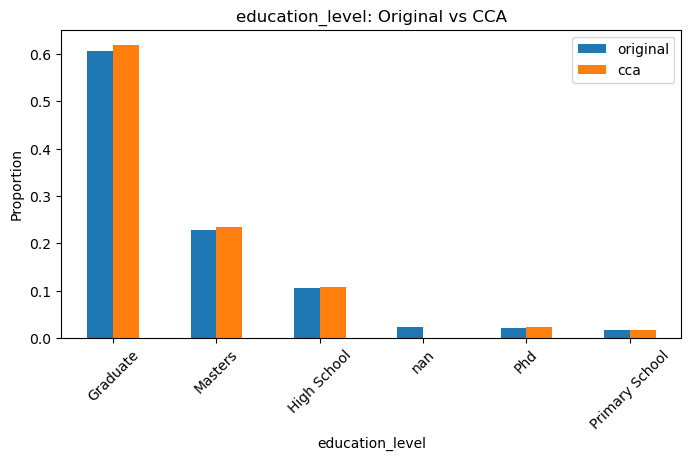

In [8]:
# ==========================================================
# 7) Compare Categorical Distributions (Original vs CCA)
# ==========================================================
def compare_category_distribution(col):
    temp = pd.concat([
        (df[col].value_counts(dropna=False) / len(df)),
        (new_df[col].value_counts(dropna=False) / len(new_df))
    ], axis=1)

    temp.columns = ['original', 'cca']
    temp = temp.fillna(0)

    print(f"\n✅ Category Distribution Comparison for: {col}")
    print(temp)

    # Plot comparison
    temp.plot(kind='bar', figsize=(8,4))
    plt.title(f"{col}: Original vs CCA")
    plt.ylabel("Proportion")
    plt.xticks(rotation=45)
    plt.show()


for col in ['enrolled_university', 'education_level']:
    if col in cols:
        compare_category_distribution(col)